<a href="https://colab.research.google.com/github/Dewatcher/cifar10-animal-object-recognizer/blob/dev/notebooks/Resnet50.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt
import torch.nn.functional as F
from torchvision import datasets, transforms
from torchvision.transforms import ToTensor
from torch.utils.data import DataLoader
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from tqdm import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [ ]:
from torchvision.models import (
    efficientnet_b3, EfficientNet_B3_Weights,
    resnet50, ResNet50_Weights,
    vgg16, VGG16_Weights,
    mobilenet_v2, MobileNet_V2_Weights,
    densenet169, DenseNet169_Weights,
    alexnet, AlexNet_Weights,
)

In [ ]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.1,
        contrast=0.1,
        saturation=0.1,
        hue=0.02
    ),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])

])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406],
                         [0.229, 0.224, 0.225])
])

In [ ]:
train_data = datasets.CIFAR10(
    root="data",
    train=True,
    download=True,
    transform=train_transform,
    target_transform=None
)

val_data = datasets.CIFAR10(
    root="data",
    train=True,
    download=True,
    transform=test_transform,
)

test_data = datasets.CIFAR10(
    root="data",
    train=False,
    download=True,
    transform=test_transform
)

100%|██████████| 170M/170M [00:17<00:00, 9.59MB/s]


In [ ]:
len(train_data.data), len(test_data.targets), len(test_data.data), len(test_data.targets)

(50000, 10000, 10000, 10000)

In [ ]:
class_names = train_data.classes
class_names

['airplane',
 'automobile',
 'bird',
 'cat',
 'deer',
 'dog',
 'frog',
 'horse',
 'ship',
 'truck']

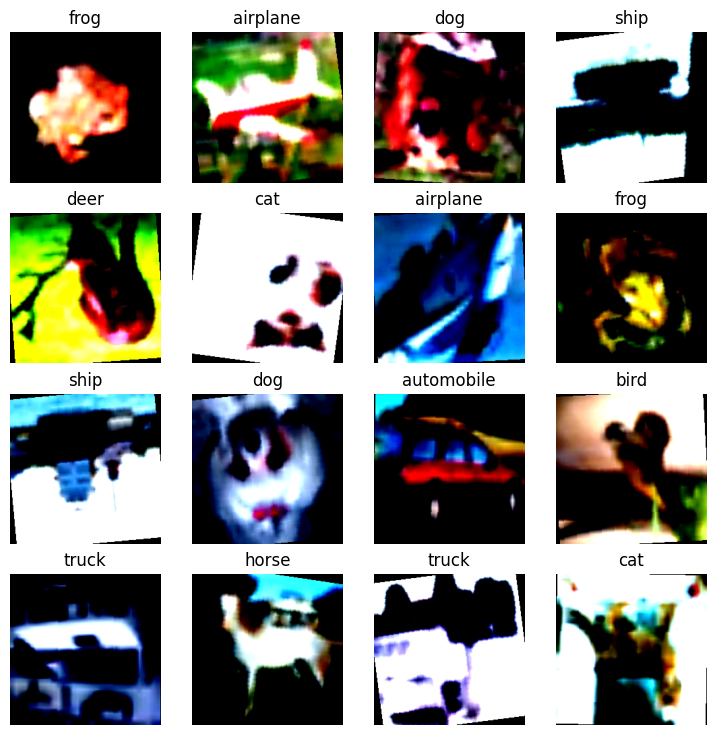

In [ ]:
import random
import matplotlib.pyplot as plt
MANUAL_SEED=42
torch.manual_seed(MANUAL_SEED)

class_names = train_data.classes
rows, cols = 4, 4
fig = plt.figure(figsize=(9, 9))

for i in range(1, rows * cols + 1):
    random_idx = random.randint(0, len(train_data) - 1)
    img, label = train_data[random_idx]
    fig.add_subplot(rows, cols, i)
    plt.imshow(img.permute(1, 2, 0))      # (3,32,32) -> (32,32,3)
    plt.title(class_names[label])
    plt.axis(False)

plt.show()

In [ ]:
from torch.utils.data.dataset import random_split
train_size = int(0.8 * len(train_data))
val_size = len(train_data) - train_size
train_subset, _ =random_split(train_data, [train_size, val_size], generator=torch.Generator().manual_seed(42))
_, val_subset = random_split(val_data, [train_size, val_size], generator=torch.Generator().manual_seed(42))

train_loader=DataLoader(train_subset, batch_size=32, shuffle=True)
val_loader=DataLoader(val_subset, batch_size=32, shuffle=False)
test_loader=DataLoader(test_data, batch_size=32, shuffle=False)

In [ ]:
print(f"Classes: {train_data.classes}")
print(f"Training samples: {train_size} images")
print(f"Validation samples: {val_size} images")
print(f"Test samples:     {len(test_data)} images")

Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Training samples: 40000 images
Validation samples: 10000 images
Test samples:     10000 images


In [ ]:
def make_pretrained_classifiers(arch_name, n_outputs=10):
  if arch_name == "resnet50":
    model = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2)
    in_features = model.fc.in_features
    model.fc = nn.Linear(in_features, n_outputs)
  else:
    raise ValueError(f"Unsupported architecture: {arch_name}")
  return model.to(device)

Starting fresh

 TRAINING: resnet50
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 158MB/s]
resnet50 Epoch 1/10: 100%|██████████| 1250/1250 [11:21<00:00,  1.83it/s]


Epoch 1/10 - Avg Loss: 0.5300
✅ Best model saved (Val Loss = 0.2217)
Epoch 1/10 | Train Loss: 0.5300 | Val Loss: 0.2217 | LR: 1.00e-04


resnet50 Epoch 2/10: 100%|██████████| 1250/1250 [11:24<00:00,  1.83it/s]


Epoch 2/10 - Avg Loss: 0.2630
✅ Best model saved (Val Loss = 0.1846)
Epoch 2/10 | Train Loss: 0.2630 | Val Loss: 0.1846 | LR: 1.00e-04


...

Epoch 8/10 - Avg Loss: 0.0928
✅ Best model saved (Val Loss = 0.1585)
Epoch 8/10 | Train Loss: 0.0928 | Val Loss: 0.1585 | LR: 1.00e-04


resnet50 Epoch 9/10: 100%|██████████| 1250/1250 [11:25<00:00,  1.82it/s]


Epoch 9/10 - Avg Loss: 0.0815
✅ Best model saved (Val Loss = 0.1566)
Epoch 9/10 | Train Loss: 0.0815 | Val Loss: 0.1566 | LR: 1.00e-04


resnet50 Epoch 10/10: 100%|██████████| 1250/1250 [11:25<00:00,  1.82it/s]


Epoch 10/10 - Avg Loss: 0.0805
✅ Best model saved (Val Loss = 0.1456)
Epoch 10/10 | Train Loss: 0.0805 | Val Loss: 0.1456 | LR: 1.00e-04


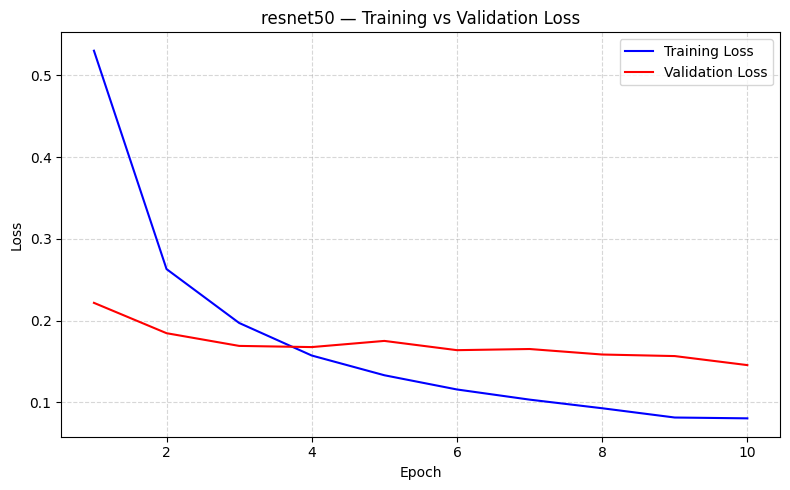

Loaded best model for resnet50 (Val Loss: 0.1456)

resnet50 — Test Accuracy: 0.9470
              precision    recall  f1-score   support

    airplane       0.94      0.96      0.95      1000
  automobile       0.98      0.97      0.97      1000
        bird       0.93      0.95      0.94      1000
         cat       0.92      0.86      0.89      1000
        deer       0.93      0.96      0.94      1000
         dog       0.90      0.92      0.91      1000
        frog       0.97      0.96      0.97      1000
       horse       0.97      0.95      0.96      1000
        ship       0.96      0.97      0.96      1000
       truck       0.96      0.96      0.96      1000

    accuracy                           0.95     10000
   macro avg       0.95      0.95      0.95     10000
weighted avg       0.95      0.95      0.95     10000

✅ Saved: resnet50 | Done so far: ['resnet50']

✅ ALL ARCHITECTURES DONE


In [ ]:
import json
import os

results = {}
if os.path.exists("results_backup.json"):
    with open("results_backup.json", "r") as f:
        results = json.load(f)
    print("Loaded existing results:", list(results.keys()))
else:
    print("Starting fresh")

loss_fn = nn.CrossEntropyLoss()
params = dict(
    batch_size=32,
    num_epochs=10,
    learning_rate=1e-4
)

architectures = [
    "resnet50"
]


for arch_name in architectures:
  if arch_name in results:
        print(f"\n⏭ Skipping {arch_name} — already saved")
        continue

  print(f"\n{'='*50}")
  print(f" TRAINING: {arch_name}")
  print(f"{'='*50}")


  standard_classifier = make_pretrained_classifiers(arch_name, n_outputs=10)
  optimizer = optim.AdamW(standard_classifier.parameters(), lr=params["learning_rate"], weight_decay=1e-4)
  scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=0.5, patience=3, min_lr=1e-7
    )

  # TRAINING
  train_losses, val_losses = [],[]
  best_loss = float("inf")
  for epoch in range(params["num_epochs"]):
     standard_classifier.train()
     epoch_train_loss = 0.0

     for x, y in tqdm(train_loader, desc=f"{arch_name} Epoch {epoch+1}/{params['num_epochs']}"):
            x = x.float().to(device)
            y = y.long().to(device)
            optimizer.zero_grad()
            logits = standard_classifier(x)
            loss = loss_fn(logits, y)
            loss.backward()
            optimizer.step()
            epoch_train_loss += loss.item()

     avg_train_loss = epoch_train_loss / len(train_loader)
     print(f"Epoch {epoch+1}/{params['num_epochs']} - Avg Loss: {avg_train_loss:.4f}")

     # Validation
     standard_classifier.eval()
     epoch_val_loss = 0.0

     with torch.inference_mode():
        for x, y in val_loader:
            x = x.float().to(device)
            y = y.long().to(device)
            logits = standard_classifier(x)
            loss   = loss_fn(logits, y)
            epoch_val_loss += loss.item()

     avg_val_loss = epoch_val_loss / len(val_loader)

     train_losses.append(avg_train_loss)
     val_losses.append(avg_val_loss)
     scheduler.step(avg_val_loss)
     if avg_val_loss < best_loss:
        best_loss = avg_val_loss

        torch.save(
              standard_classifier.state_dict(),
              f"{arch_name}_best.pth"
           )

        print(f"✅ Best model saved (Val Loss = {best_loss:.4f})")
     print(
      f"Epoch {epoch+1}/{params['num_epochs']} | "
      f"Train Loss: {avg_train_loss:.4f} | "
      f"Val Loss: {avg_val_loss:.4f} | "
      f"LR: {optimizer.param_groups[0]['lr']:.2e}"
      )

  plt.figure(figsize=(8, 5))
  plt.plot(range(1, len(train_losses)+1), train_losses, label="Training Loss",   color="blue")
  plt.plot(range(1, len(val_losses)+1),   val_losses,   label="Validation Loss", color="red")
  plt.xlabel("Epoch")
  plt.ylabel("Loss")
  plt.title(f"{arch_name} — Training vs Validation Loss")
  plt.legend()
  plt.grid(True, linestyle='--', alpha=0.5)
  plt.tight_layout()
  plt.show()



  # EVALUATION
  # Add this right before standard_classifier.eval() in evaluation block
  standard_classifier.load_state_dict(torch.load(f"{arch_name}_best.pth"))
  standard_classifier = standard_classifier.to(device)
  print(f"Loaded best model for {arch_name} (Val Loss: {best_loss:.4f})")
  standard_classifier.eval()
  all_preds, all_labels = [], []

  with torch.inference_mode():
      for x, y in test_loader:
           x = x.float().to(device)
           logits = standard_classifier(x)
           preds = logits.argmax(dim=1)
           all_preds.extend(preds.cpu().numpy())
           all_labels.extend(y.numpy())


  all_preds  = np.array(all_preds)
  all_labels = np.array(all_labels)


  report = classification_report(
        all_labels, all_preds,
        target_names=class_names,
        output_dict=True
     )

  print(f"\n{arch_name} — Test Accuracy: {report['accuracy']:.4f}")
  print(classification_report(all_labels, all_preds, target_names=class_names))

  # ── SAVE ──────────────────────────────────────────────
  results[arch_name] = {
        "Accuracy":            round(report["accuracy"], 4),
        "Macro Precision":     round(report["macro avg"]["precision"], 4),
        "Macro Recall":        round(report["macro avg"]["recall"], 4),
        "Best Val Loss":       round(best_loss, 4),
        "Final Train Loss":    round(train_losses[-1], 4),
        "Macro F1":            round(report["macro avg"]["f1-score"], 4),
     }

  with open("results_backup.json", "w") as f:
        json.dump(results, f)
  print(f"✅ Saved: {arch_name} | Done so far: {list(results.keys())}")

  del standard_classifier, optimizer, scheduler
  torch.cuda.empty_cache()

print("\n✅ ALL ARCHITECTURES DONE")

In [ ]:
import os
print(os.path.exists("resnet50_best.pth"))

True


In [ ]:
import shutil, os
os.makedirs("app", exist_ok=True)
shutil.copy("resnet50_best.pth", "app/resnet50_cifar10.pth")
print(os.path.getsize("app/resnet50_cifar10.pth") / 1e6, "MB")

94.434019 MB


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!cp /content/app/resnet50_cifar10.pth /content/drive/MyDrive/resnet50_cifar10.pth

Mounted at /content/drive


In [ ]:
%cd /content
!pip install -q streamlit
!rm -rf run && git clone -q -b dev https://github.com/Dewatcher/cifar10-animal-object-recognizer.git run
!ls -lh run/app
!grep -n "Resize\|Normalize\|weights=None\|\.pth" run/app/app.py

/content
total 133M
-rw-r--r-- 1 root root 3.8K Oct 10 19:32 app.py
-rw-r--r-- 1 root root  43M Oct 10 19:32 cifar10_resnet18_adas.pth
-rw-r--r-- 1 root root    7 Oct 10 19:32 README.md
-rw-r--r-- 1 root root  91M Oct 10 19:32 resnet50_cifar10.pth
34:MODEL_PATH = os.path.join(os.path.dirname(os.path.abspath(__file__)), "resnet50_cifar10.pth")
38:    model = resnet50(weights=None)
48:    transforms.Resize((32, 32)),
49:    transforms.Resize((224, 224)),
51:    transforms.Normalize([0.485, 0.456, 0.406],


In [ ]:
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
!chmod +x cloudflared
!nohup streamlit run /content/run/app/app.py --server.port 8501 --server.headless true > st.log 2>&1 &
!nohup ./cloudflared tunnel --url http://localhost:8501 > cf.log 2>&1 &
import time; time.sleep(8)
!grep -o "https://[a-z0-9-]*\.trycloudflare\.com" cf.log | head -1

cloudflared: Text file busy
https://preservation-perfectly-comp-code.trycloudflare.com


In [ ]:
from PIL import Image
img = Image.open("car.png").convert("RGB")
img.resize((32, 32)).save("car_32.png")

FileNotFoundError: [Errno 2] No such file or directory: 'car.png'